# Decoding detector error models

In this experiment, we decode circuit-level noise with ``mdopt``. Instead of a code and a Pauli error, the input is a [stim](https://github.com/quantumlib/Stim) detector error model (DEM): a list of independent error mechanisms, each firing with a known prior probability and flipping a known set of detectors and logical observables.

Decoding a DEM is a purely classical problem. Every mechanism becomes one MPS site, every detector becomes a parity-check (XOR) constraint, and every logical observable becomes a readout site at the front of the chain. Contracting the constraints and marginalizing the mechanisms leaves the total probability mass of each observable-flip class, and the decoder returns the most likely class. This is maximum-likelihood decoding, exact at large enough bond dimension.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import stim
from scipy.stats import sem
from tqdm import tqdm

from mdopt.decoding import decode_dem, dem_to_problem
from mdopt.decoding.dem import constraint_spans, order_mechanisms

try:
    import pymatching
except ImportError:  # optional: only the comparison below needs it
    pymatching = None

# NumPy 2 reprs scalars as np.int64(0); this restores the plain 0 in outputs.
np.set_printoptions(legacy="1.25")

# CI runs this notebook with MDOPT_NB_FAST=1 to keep the job minutes rather
# than hours; the committed outputs come from a full-scale run.
FAST = bool(os.environ.get("MDOPT_NB_FAST"))

## From a circuit to a decoding problem

We take stim's rotated surface code memory experiment at distance 3 with 3 rounds of syndrome extraction, and apply the same depolarizing strength after every Clifford gate, before every measurement and after every reset. Maximum-likelihood decoding needs the undecomposed hyperedges, so the DEM is built with ``decompose_errors=False``; ``flatten_loops=True`` unrolls the repeated rounds. ``dem_to_problem`` merges mechanisms with identical detector and observable footprints into one site.

In [2]:
DISTANCE, ROUNDS = 3, 3


def memory_circuit(p, distance=DISTANCE, rounds=ROUNDS):
    """Rotated surface code X-memory experiment with uniform circuit noise."""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_x",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=p,
        before_measure_flip_probability=p,
        after_reset_flip_probability=p,
    )


circuit = memory_circuit(0.008)
dem = circuit.detector_error_model(decompose_errors=False, flatten_loops=True)
problem = dem_to_problem(dem)

print(f"Error mechanisms:    {problem.num_mechanisms}")
print(f"Detectors:           {problem.num_detectors}")
print(f"Logical observables: {problem.num_observables}")
print(f"Chain length:        {problem.num_mechanisms + problem.num_observables} sites")

Error mechanisms:    221
Detectors:           24
Logical observables: 1
Chain length:        222 sites


## Decoding one shot

We sample detection events together with the true observable flips, and decode a shot with a nonzero syndrome. ``decode_dem`` returns one non-normalized probability mass per observable-flip class (bit ``j`` of the class index is observable ``j``) and the most likely class as a bit array.

In [3]:
sampler = circuit.compile_detector_sampler(seed=1)
detections, observables = sampler.sample(200, separate_observables=True)
detections, observables = detections.astype(int), observables.astype(int)

shot = int(np.flatnonzero(detections.sum(axis=1) >= 3)[0])
syndrome = detections[shot]
print("Fired detectors:", np.flatnonzero(syndrome).tolist())

class_masses, predicted_flips = decode_dem(problem, syndrome, chi_max=32)
print("Class probabilities:", np.round(class_masses / class_masses.sum(), 4))
print("Predicted observable flips:", predicted_flips)
print("Actual observable flips:   ", observables[shot])

Fired detectors: [0, 1, 4, 6]


Class probabilities: [0.9047 0.0953]
Predicted observable flips: [0]
Actual observable flips:    [0]


## Convergence in the bond dimension

A successful contraction does not by itself certify convergence: at small ``chi_max`` the truncations discard probability mass and can bias the class weights. The reliable check is a ladder, decoding the same syndrome at increasing ``chi_max`` until the normalized class weights stop moving. Below, the shots with the most fired detectors are the hardest to converge.

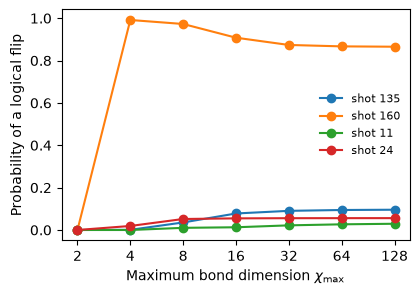

In [4]:
CHI_LADDER = [2, 4, 8, 16, 32] if FAST else [2, 4, 8, 16, 32, 64, 128]
hard_shots = np.argsort(-detections.sum(axis=1), kind="stable")[:4]

weights = {}
for s in hard_shots:
    weights[s] = []
    for chi in CHI_LADDER:
        masses, _ = decode_dem(problem, detections[s], chi_max=chi)
        weights[s].append(masses[1] / masses.sum())

fig, ax = plt.subplots(figsize=(4.5, 3))
for s in hard_shots:
    ax.plot(CHI_LADDER, weights[s], marker="o", label=f"shot {s}")
ax.set_xscale("log", base=2)
ax.set_xticks(CHI_LADDER, [str(chi) for chi in CHI_LADDER])
ax.set_xlabel(r"Maximum bond dimension $\chi_{\max}$")
ax.set_ylabel("Probability of a logical flip")
ax.legend(frameon=False, fontsize=8)
plt.show()

At $\chi_{\max} = 2$ the truncation discards every flipped configuration and all four shots read zero. From there the weights rise and flatten out by $\chi_{\max} = 32$. At $\chi_{\max} = 16$ they are still a few percent from their converged values, but every shot already lands on the same side of one half, so the predicted class is final. The Monte Carlo below runs at $\chi_{\max} = 16$ to keep it cheap; a run quoting class probabilities, not just predictions, would use the converged end of the ladder.

## Mechanism ordering

The cost of a finite-``chi_max`` contraction is governed by how far each detector constraint stretches along the chain: the span (last site minus first site) counts the SWAP tensors the constraint drags along. ``order_mechanisms`` can reorder the mechanisms with reverse Cuthill-McKee, the bandwidth minimizer the code decoders use for qubit order. On circuit-level DEMs, however, stim's native order is already time-ordered, and the reordering makes the spans worse.

Mean span, stim order:           71.5
Mean span, reverse Cuthill-McKee: 101.8


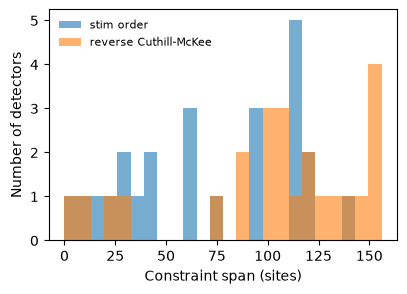

In [5]:
reordered, perm = order_mechanisms(problem, strategy="bandwidth")
spans_natural = constraint_spans(problem)
spans_bandwidth = constraint_spans(reordered)
print(f"Mean span, stim order:           {spans_natural.mean():.1f}")
print(f"Mean span, reverse Cuthill-McKee: {spans_bandwidth.mean():.1f}")

fig, ax = plt.subplots(figsize=(4.5, 3))
bins = np.linspace(0, max(spans_natural.max(), spans_bandwidth.max()), 25)
ax.hist(spans_natural, bins=bins, alpha=0.6, label="stim order")
ax.hist(spans_bandwidth, bins=bins, alpha=0.6, label="reverse Cuthill-McKee")
ax.set_xlabel("Constraint span (sites)")
ax.set_ylabel("Number of detectors")
ax.legend(frameon=False, fontsize=8)
plt.show()

The decoded posterior does not depend on the order, only the cost does, so we keep stim's order.

## Logical error rate

Finally, we estimate the logical error rate over a range of physical error rates. When ``pymatching`` is installed (it ships with the ``test`` dependency group), every shot is also decoded with minimum-weight perfect matching on the decomposed DEM for comparison. Maximum likelihood should never do worse than matching, up to sampling noise.

In [6]:
CHI_MAX = 16
ERROR_RATES = [0.004, 0.008] if FAST else [0.002, 0.004, 0.006, 0.008, 0.010]
NUM_SHOTS = 20 if FAST else 2000

results = {}
for p in ERROR_RATES:
    circ = memory_circuit(p)
    prob = dem_to_problem(circ.detector_error_model(decompose_errors=False, flatten_loops=True))
    dets, obs = circ.compile_detector_sampler(seed=7).sample(NUM_SHOTS, separate_observables=True)
    dets, obs = dets.astype(int), obs.astype(int)

    start = time.perf_counter()
    failures_mps = np.array(
        [
            np.any(decode_dem(prob, d, chi_max=CHI_MAX)[1] != o)
            for d, o in tqdm(zip(dets, obs), total=NUM_SHOTS, desc=f"p = {p}", disable=FAST)
        ]
    )
    elapsed = time.perf_counter() - start
    results[p] = {"mps": failures_mps, "seconds_per_shot": elapsed / NUM_SHOTS}

    if pymatching is not None:
        matching = pymatching.Matching.from_detector_error_model(
            circ.detector_error_model(decompose_errors=True)
        )
        predictions = matching.decode_batch(dets.astype(np.uint8))
        results[p]["mwpm"] = np.any(predictions != obs, axis=1)

for p, r in results.items():
    line = f"p = {p:.3f}: MPS {r['mps'].mean():.4f} ± {sem(r['mps']):.4f}"
    if "mwpm" in r:
        line += f", MWPM {r['mwpm'].mean():.4f} ± {sem(r['mwpm']):.4f}"
    print(line + f"  ({r['seconds_per_shot']:.2f} s per shot)")

p = 0.01: 100%|██████████| 2000/2000 [06:29<00:00,  5.13it/s]


p = 0.002: MPS 0.0020 ± 0.0010, MWPM 0.0030 ± 0.0012  (0.19 s per shot)
p = 0.004: MPS 0.0060 ± 0.0017, MWPM 0.0095 ± 0.0022  (0.19 s per shot)
p = 0.006: MPS 0.0120 ± 0.0024, MWPM 0.0150 ± 0.0027  (0.19 s per shot)
p = 0.008: MPS 0.0240 ± 0.0034, MWPM 0.0270 ± 0.0036  (0.19 s per shot)
p = 0.010: MPS 0.0360 ± 0.0042, MWPM 0.0410 ± 0.0044  (0.19 s per shot)


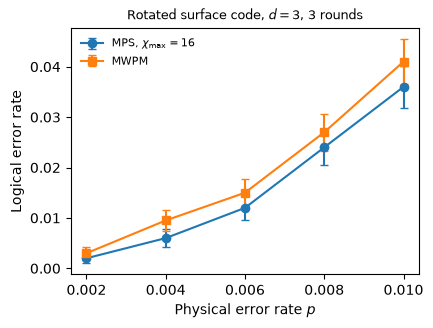

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ps = list(results)
for key, label, marker in [("mps", rf"MPS, $\chi_{{\max}} = {CHI_MAX}$", "o"), ("mwpm", "MWPM", "s")]:
    if all(key in results[p] for p in ps):
        means = [results[p][key].mean() for p in ps]
        errs = [sem(results[p][key]) for p in ps]
        ax.errorbar(ps, means, yerr=errs, marker=marker, capsize=3, label=label)
ax.set_xlabel("Physical error rate $p$")
ax.set_ylabel("Logical error rate")
ax.set_title(f"Rotated surface code, $d = {DISTANCE}$, {ROUNDS} rounds", fontsize=9)
ax.legend(frameon=False, fontsize=8)
plt.show()

The MPS decoder tracks or improves on matching at every error rate, as maximum likelihood should. The larger-scale harnesses behind the decoder's validation (code-capacity thresholds against matching, a distance-5 circuit-level cell decoded on a per-shot bond-dimension ladder, and a reproduction of Fig. 1d of Piveteau, Chubb and Renes, PRX Quantum 5, 040303) live in [``examples/decoding/dem_campaign``](https://github.com/quicophy/mdopt/tree/main/examples/decoding/dem_campaign).